# 11. K-Means Clustering

정답(income) 없이 비슷한 사람끼리 묶는다.
묶은 뒤에만 각 클러스터의 >50K 비율을 본다. (분류 모델 비교용 아님)

In [2]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

from src.data import load_adult
from src.preprocess import split_features_target, build_preprocessor

X, y = split_features_target(load_adult("train"))

pre = build_preprocessor()
Xt = pre.fit_transform(X)

if hasattr(Xt, "toarray"):
    Xt = Xt.toarray()

print(X.shape, Xt.shape, y.mean())

(32561, 12) (32561, 71) 0.2408095574460244


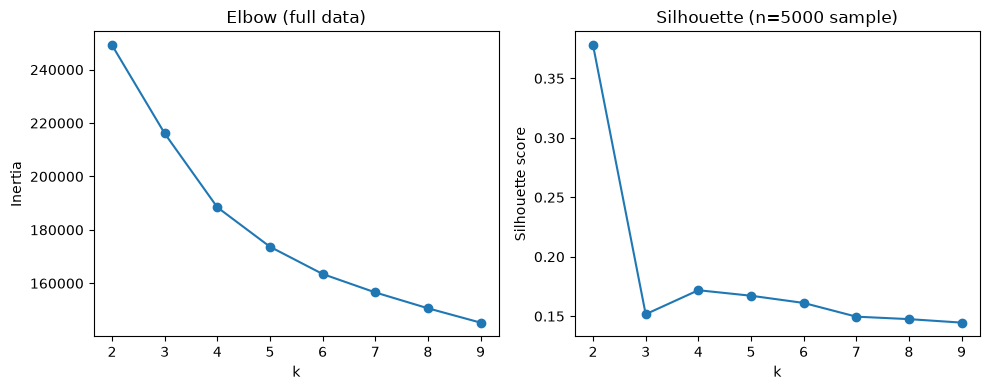

inertia: {2: np.float64(249158.4), 3: np.float64(216107.8), 4: np.float64(188449.0), 5: np.float64(173681.5), 6: np.float64(163475.8), 7: np.float64(156576.6), 8: np.float64(150639.7), 9: np.float64(145267.5)}
silhouette: {2: np.float64(0.3779), 3: np.float64(0.1517), 4: np.float64(0.1719), 5: np.float64(0.1672), 6: np.float64(0.1612), 7: np.float64(0.1496), 8: np.float64(0.1476), 9: np.float64(0.1446)}


In [4]:
k_values = range(2, 10)

# just for silhouette score
rng = np.random.default_rng(42)
idx = rng.choice(len(Xt), size=5000, replace=False)
Xt_sample = Xt[idx]

inertias = []
silhouette_scores = []

for k in k_values:
    # Elbow: all cases
    km_full = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_full.fit(Xt)
    inertias.append(km_full.inertia_)

    # Silhouette: 5000 cases(takes too long)
    km_s = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_s = km_s.fit_predict(Xt_sample)
    silhouette_scores.append(silhouette_score(Xt_sample, labels_s))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow (full data)")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette (n=5000 sample)")

plt.tight_layout()
plt.show()

print("inertia:", dict(zip(k_values, np.round(inertias, 1))))
print("silhouette:", dict(zip(k_values, np.round(silhouette_scores, 4))))

In [5]:
BEST_K = 2
km = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
labels = km.fit_predict(Xt)

summary = (
    pd.DataFrame({"cluster": labels, "high_income": y})
    .groupby("cluster")
    .agg(
        n=("high_income", "size"),
        high_income_rate=("high_income", "mean"),
    )
)
summary["high_income_rate"] = (summary["high_income_rate"] * 100).round(1)
print(summary)
print("all >50K rate(%):", round(y.mean() * 100, 1))

             n  high_income_rate
cluster                         
0        29855              20.6
1         2706              62.0
all >50K rate(%): 24.1
